# Which Machine Learning Classifier Should You Choose?

## Comparing Multiple Classification Algorithms Using the Wine Dataset

In this notebook, we will build an end-to-end machine learning classification workflow.

We will train and compare:

1. Logistic Regression
2. K-Nearest Neighbors (KNN)
3. Decision Tree
4. Random Forest
5. Support Vector Machine (SVM)
6. Gradient Boosting

Our goal is not simply to find the model with the highest accuracy.

We will investigate:

- How different classifiers behave on the same dataset
- Why preprocessing matters
- How model predictions differ
- Accuracy, Precision, Recall and F1-score
- Confusion matrices
- ROC-AUC
- Training time
- Overall model comparison

Finally, we will answer:

> Which classifier should we choose?

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from time import time

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

## Step 1: Load the Dataset

The Wine dataset is built directly into scikit-learn.

Each observation represents a wine sample.

The features describe chemical properties of the wine.

The target represents the wine class.

In [ ]:
wine = load_wine()

X = wine.data
y = wine.target

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Feature matrix shape: (178, 13)
Target shape: (178,)


In [ ]:
#understand the data
print("Feature names:")
for i, feature in enumerate(wine.feature_names, start=1):
    print(i, feature)

print("\nTarget classes:")
print(wine.target_names)

Feature names:
1 alcohol
2 malic_acid
3 ash
4 alcalinity_of_ash
5 magnesium
6 total_phenols
7 flavanoids
8 nonflavanoid_phenols
9 proanthocyanins
10 color_intensity
11 hue
12 od280/od315_of_diluted_wines
13 proline

Target classes:
['class_0' 'class_1' 'class_2']


In [ ]:
#create Dataframe
df = pd.DataFrame(X, columns=wine.feature_names)

df["target"] = y

df.tail(7)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
171,12.77,2.39,2.28,19.5,86.0,1.39,0.51,0.48,0.64,9.899999,0.57,1.63,470.0,2
172,14.16,2.51,2.48,20.0,91.0,1.68,0.70,0.44,1.24,9.700000,0.62,1.71,660.0,2
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.700000,0.64,1.74,740.0,2
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.300000,0.70,1.56,750.0,2
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.200000,0.59,1.56,835.0,2
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.300000,0.60,1.62,840.0,2
177,14.13,4.10,2.74,24.5,96.0,2.05,0.76,0.56,1.35,9.200000,0.61,1.60,560.0,2


In [ ]:
df.shape

(178, 14)

In [ ]:
df.info

<bound method DataFrame.info of      alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0      14.23        1.71  2.43               15.6      127.0           2.80   
1      13.20        1.78  2.14               11.2      100.0           2.65   
2      13.16        2.36  2.67               18.6      101.0           2.80   
3      14.37        1.95  2.50               16.8      113.0           3.85   
4      13.24        2.59  2.87               21.0      118.0           2.80   
..       ...         ...   ...                ...        ...            ...   
173    13.71        5.65  2.45               20.5       95.0           1.68   
174    13.40        3.91  2.48               23.0      102.0           1.80   
175    13.27        4.28  2.26               20.0      120.0           1.59   
176    13.17        2.59  2.37               20.0      120.0           1.65   
177    14.13        4.10  2.74               24.5       96.0           2.05   

     flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0          3.06                  0.28             2.29             5.64  1.04   
1          2.76                  0.26             1.28             4.38  1.05   
2          3.24                  0.30             2.81             5.68  1.03   
3          3.49                  0.24             2.18             7.80  0.86   
4          2.69                  0.39             1.82             4.32  1.04   
..          ...                   ...              ...              ...   ...   
173        0.61                  0.52             1.06             7.70  0.64   
174        0.75                  0.43             1.41             7.30  0.70   
175        0.69                  0.43             1.35            10.20  0.59   
176        0.68                  0.53             1.46             9.30  0.60   
177        0.76                  0.56             1.35             9.20  0.61   

     od280/od315_of_diluted_wines  proline  target  
0                            3.92   1065.0       0  
1                            3.40   1050.0       0  
2                            3.17   1185.0       0  
3                            3.45   1480.0       0  
4                            2.93    735.0       0  
..                            ...      ...     ...  
173                          1.74    740.0       2  
174                          1.56    750.0       2  
175                          1.56    835.0       2  
176                          1.62    840.0       2  
177                          1.60    560.0       2  

[178 rows x 14 columns]>

In [ ]:
df.describe

<bound method NDFrame.describe of      alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0      14.23        1.71  2.43               15.6      127.0           2.80   
1      13.20        1.78  2.14               11.2      100.0           2.65   
2      13.16        2.36  2.67               18.6      101.0           2.80   
3      14.37        1.95  2.50               16.8      113.0           3.85   
4      13.24        2.59  2.87               21.0      118.0           2.80   
..       ...         ...   ...                ...        ...            ...   
173    13.71        5.65  2.45               20.5       95.0           1.68   
174    13.40        3.91  2.48               23.0      102.0           1.80   
175    13.27        4.28  2.26               20.0      120.0           1.59   
176    13.17        2.59  2.37               20.0      120.0           1.65   
177    14.13        4.10  2.74               24.5       96.0           2.05   

     flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0          3.06                  0.28             2.29             5.64  1.04   
1          2.76                  0.26             1.28             4.38  1.05   
2          3.24                  0.30             2.81             5.68  1.03   
3          3.49                  0.24             2.18             7.80  0.86   
4          2.69                  0.39             1.82             4.32  1.04   
..          ...                   ...              ...              ...   ...   
173        0.61                  0.52             1.06             7.70  0.64   
174        0.75                  0.43             1.41             7.30  0.70   
175        0.69                  0.43             1.35            10.20  0.59   
176        0.68                  0.53             1.46             9.30  0.60   
177        0.76                  0.56             1.35             9.20  0.61   

     od280/od315_of_diluted_wines  proline  target  
0                            3.92   1065.0       0  
1                            3.40   1050.0       0  
2                            3.17   1185.0       0  
3                            3.45   1480.0       0  
4                            2.93    735.0       0  
..                            ...      ...     ...  
173                          1.74    740.0       2  
174                          1.56    750.0       2  
175                          1.56    835.0       2  
176                          1.62    840.0       2  
177                          1.60    560.0       2  

[178 rows x 14 columns]>

In [ ]:
#class distribution
df["target"].value_counts().sort_index()

,count
target,
0,59
1,71
2,48


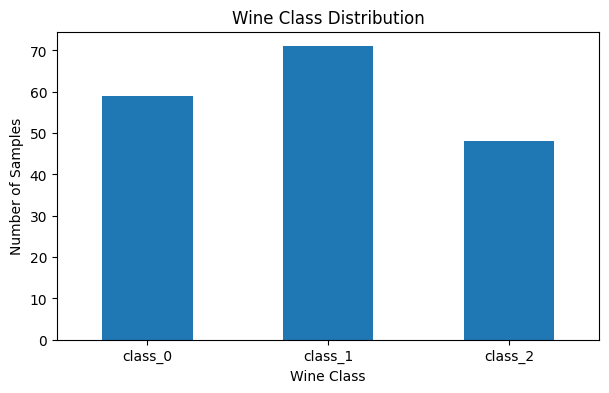

In [ ]:
#visualization
plt.figure(figsize=(7, 4))

df["target"].value_counts().sort_index().plot(kind="bar")

plt.xlabel("Wine Class")
plt.ylabel("Number of Samples")
plt.title("Wine Class Distribution")
plt.xticks(
    ticks=[0, 1, 2],
    labels=wine.target_names,
    rotation=0
)

plt.show()

## Features vs Target

X contains the input features.

y contains the class we want to predict.

Our task is:

Chemical properties → Wine Class

In [ ]:
#separate features and target
X = wine.data
y = wine.target

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (178, 13)
y shape: (178,)


In [ ]:
#train test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 124
Testing samples: 54


In [ ]:
stratify=y
#This keeps the class proportions approximately similar in training and testing sets.

## Why Do We Need Feature Scaling?

The 13 features are measured on different scales.

For example:

- Alcohol
- Magnesium
- Proline
- Color intensity

Some features have much larger numerical values than others.

Distance-based and margin-based algorithms can be strongly affected by these differences.

Therefore, we will use StandardScaler for:

- Logistic Regression
- KNN
- SVM

Tree-based models do not require feature scaling.

In [ ]:
#Build six classifiers
#recommend putting them in a dictionary
models = {

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000))
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(
            probability=True,
            random_state=42
        ))
    ]),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

In [ ]:
#Train the models
results = []

trained_models = {}

for name, model in models.items():

    start_time = time()

    model.fit(X_train, y_train)

    training_time = time() - start_time

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        average="weighted"
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="weighted"
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="weighted"
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Training Time": training_time
    })

    trained_models[name] = model

In [ ]:
#create comparison table
results_df = pd.DataFrame(results)

results_df.sort_values(
    by="F1 Score",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score,Training Time
3,Random Forest,1.000000,1.000000,1.000000,1.000000,0.487360
0,Logistic Regression,0.981481,0.982456,0.981481,0.981506,0.065008
4,SVM,0.981481,0.982323,0.981481,0.981378,0.023186
2,Decision Tree,0.962963,0.966184,0.962963,0.963221,0.010935
5,Gradient Boosting,0.962963,0.966184,0.962963,0.962715,1.227386
1,KNN,0.944444,0.953704,0.944444,0.944833,0.004849


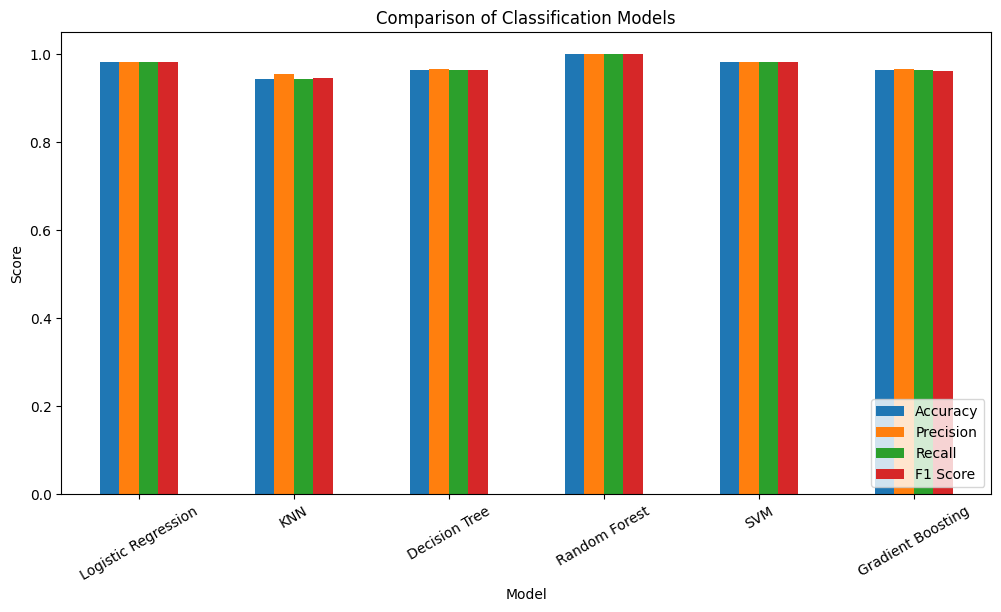

In [ ]:
#visual model comparison
comparison = results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
]

comparison.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparison of Classification Models")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=30)
plt.legend(loc="lower right")

plt.show()

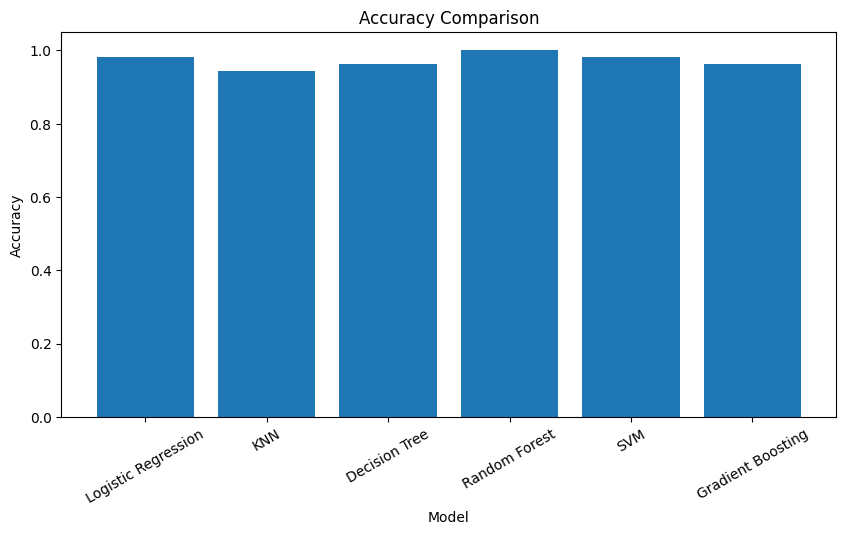

In [ ]:
#accuracy comparison
plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"]
)

plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.title("Accuracy Comparison")

plt.ylim(0, 1.05)
plt.xticks(rotation=30)

plt.show()

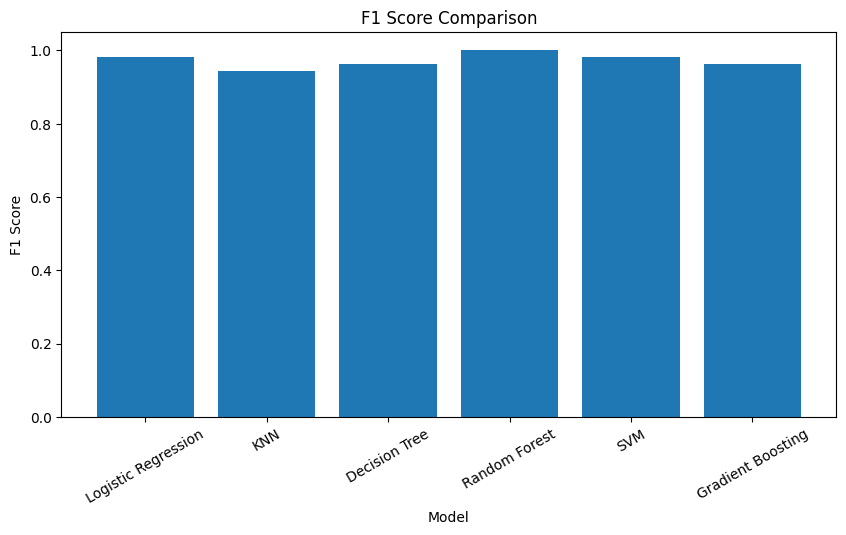

In [ ]:
#F1 score comparison
plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["F1 Score"]
)

plt.ylabel("F1 Score")
plt.xlabel("Model")
plt.title("F1 Score Comparison")

plt.ylim(0, 1.05)
plt.xticks(rotation=30)

plt.show()

In [ ]:
# Detailed Classification Report
for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    print("=" * 70)
    print(name)
    print("=" * 70)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=wine.target_names
        )
    )

Logistic Regression
              precision    recall  f1-score   support

     class_0       0.95      1.00      0.97        18
     class_1       1.00      0.95      0.98        21
     class_2       1.00      1.00      1.00        15

    accuracy                           0.98        54
   macro avg       0.98      0.98      0.98        54
weighted avg       0.98      0.98      0.98        54

KNN
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        18
     class_1       1.00      0.86      0.92        21
     class_2       0.83      1.00      0.91        15

    accuracy                           0.94        54
   macro avg       0.94      0.95      0.94        54
weighted avg       0.95      0.94      0.94        54

Decision Tree
              precision    recall  f1-score   support

     class_0       1.00      0.94      0.97        18
     class_1       0.91      1.00      0.95        21
     class_2       1.00      0.93    

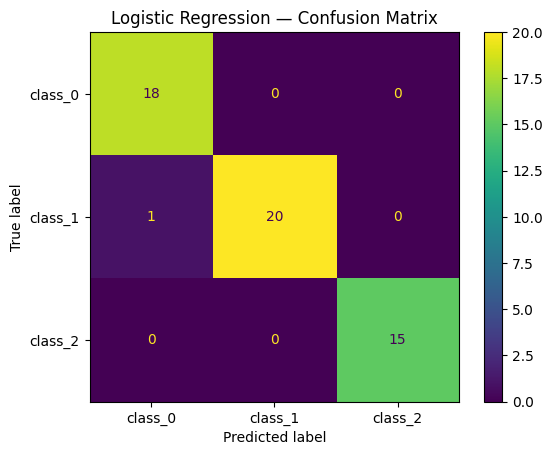

In [ ]:
# confusion matrix (Logistic Regression)
model = trained_models["Logistic Regression"]

y_pred = model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=wine.target_names
)

disp.plot()

plt.title("Logistic Regression — Confusion Matrix")
plt.show()

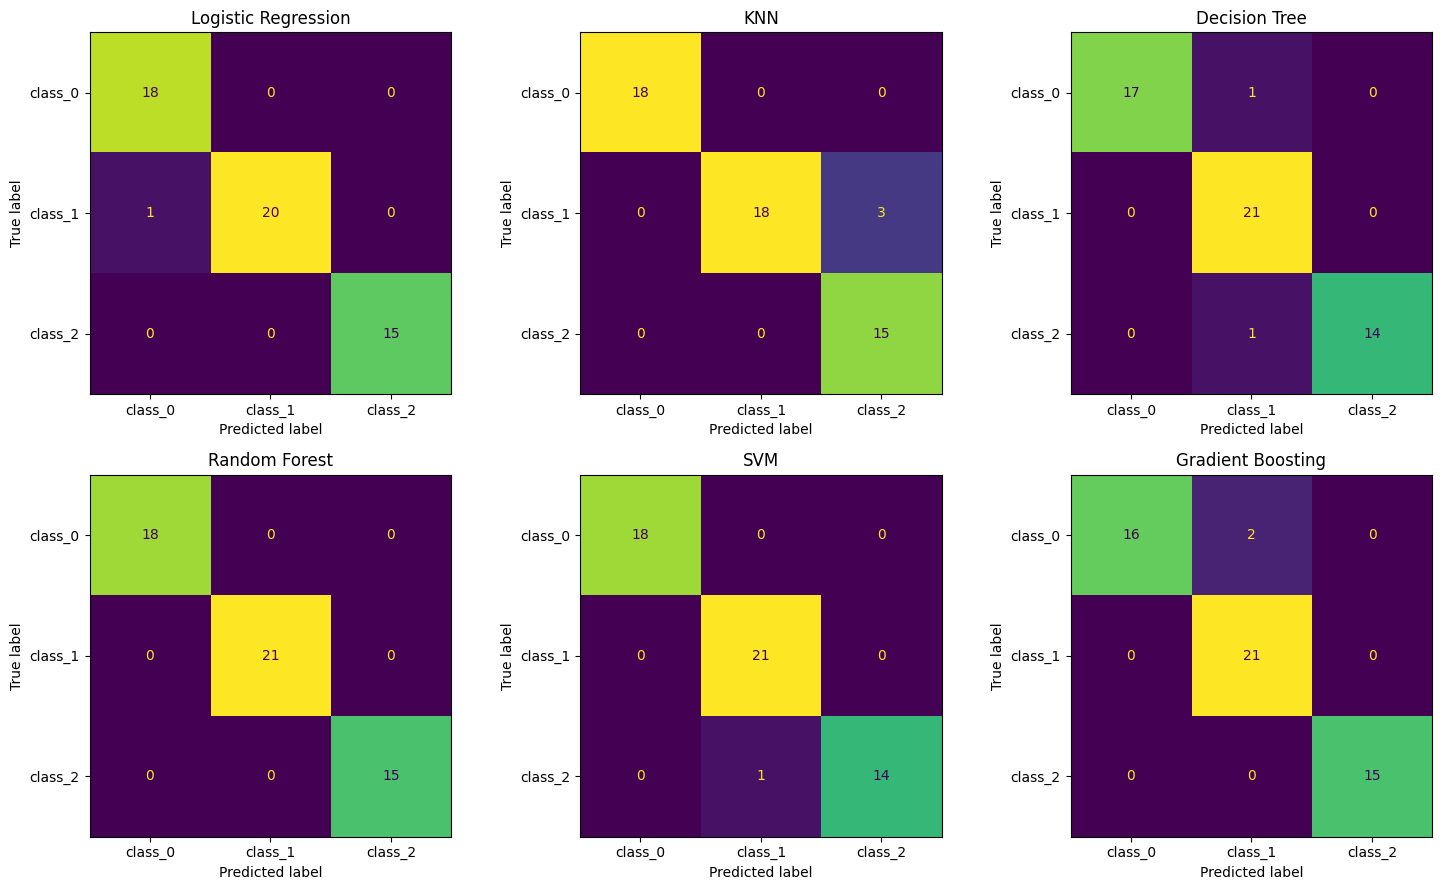

In [ ]:
# confusion matrix (All Models)
fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 9)
)

for ax, (name, model) in zip(
    axes.ravel(),
    trained_models.items()
):

    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=wine.target_names
    )

    disp.plot(
        ax=ax,
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

In [ ]:
# pick one test sample, and predict
sample_index = 0

sample = X_test[sample_index].reshape(1, -1)

actual_class = y_test[sample_index]

print(
    "Actual class:",
    wine.target_names[actual_class]
)

Actual class: class_0


In [ ]:
for name, model in trained_models.items():

    prediction = model.predict(sample)[0]

    probabilities = model.predict_proba(sample)[0]

    print("\n", name)

    print(
        "Predicted class:",
        wine.target_names[prediction]
    )

    print(
        "Probabilities:",
        probabilities
    )

    #Notice that all models receive exactly the same wine sample, but they can produce different predictions and different confidence distributions.


 Logistic Regression
Predicted class: class_0
Probabilities: [9.90734414e-01 8.83183589e-03 4.33749989e-04]

 KNN
Predicted class: class_0
Probabilities: [1. 0. 0.]

 Decision Tree
Predicted class: class_0
Probabilities: [1. 0. 0.]

 Random Forest
Predicted class: class_0
Probabilities: [0.95 0.03 0.02]

 SVM
Predicted class: class_0
Probabilities: [0.98576192 0.00728978 0.0069483 ]

 Gradient Boosting
Predicted class: class_0
Probabilities: [9.99998186e-01 1.22206767e-06 5.91652450e-07]


In [ ]:
# compare prediction of every test sample
prediction_comparison = pd.DataFrame({
    "Actual": y_test
})

for name, model in trained_models.items():

    prediction_comparison[name] = model.predict(X_test)

prediction_comparison.head(20)

,Actual,Logistic Regression,KNN,Decision Tree,Random Forest,SVM,Gradient Boosting
0,0,0,0,0,0,0,0
1,1,1,1,1,1,1,1
2,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0
4,0,0,0,1,0,0,0
5,0,0,0,0,0,0,0
6,2,2,2,2,2,2,2
7,1,1,1,1,1,1,1
8,1,1,1,1,1,1,1
9,2,2,2,2,2,1,2


In [ ]:
# convert class numbers into names
prediction_comparison_named = prediction_comparison.copy()

prediction_comparison_named = prediction_comparison_named.replace({
    0: wine.target_names[0],
    1: wine.target_names[1],
    2: wine.target_names[2]
})

prediction_comparison_named.head(20)

,Actual,Logistic Regression,KNN,Decision Tree,Random Forest,SVM,Gradient Boosting
0,class_0,class_0,class_0,class_0,class_0,class_0,class_0
1,class_1,class_1,class_1,class_1,class_1,class_1,class_1
2,class_0,class_0,class_0,class_0,class_0,class_0,class_0
3,class_0,class_0,class_0,class_0,class_0,class_0,class_0
4,class_0,class_0,class_0,class_1,class_0,class_0,class_0
5,class_0,class_0,class_0,class_0,class_0,class_0,class_0
6,class_2,class_2,class_2,class_2,class_2,class_2,class_2
7,class_1,class_1,class_1,class_1,class_1,class_1,class_1
8,class_1,class_1,class_1,class_1,class_1,class_1,class_1
9,class_2,class_2,class_2,class_2,class_2,class_1,class_2
